<a href="https://colab.research.google.com/gist/jonghank/1462892b63f07b02bc72484ad8388592/ase3001_exercises_image_filtering_2026a.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Image filtering


$$
\newcommand{\eg}{{\it e.g.}}
\newcommand{\ie}{{\it i.e.}}
\newcommand{\argmin}{\operatornamewithlimits{argmin}}
\newcommand{\mc}{\mathcal}
\newcommand{\mb}{\mathbb}
\newcommand{\mf}{\mathbf}
\newcommand{\minimize}{{\text{minimize}}}
\newcommand{\diag}{{\text{diag}}}
\newcommand{\cond}{{\text{cond}}}
\newcommand{\rank}{{\text{rank }}}
\newcommand{\range}{{\mathcal{R}}}
\newcommand{\null}{{\mathcal{N}}}
\newcommand{\tr}{{\text{trace}}}
\newcommand{\dom}{{\text{dom}}}
\newcommand{\dist}{{\text{dist}}}
\newcommand{\R}{\mathbf{R}}
\newcommand{\SM}{\mathbf{S}}
\newcommand{\ball}{\mathcal{B}}
\newcommand{\bmat}[1]{\begin{bmatrix}#1\end{bmatrix}}
\newcommand{\loss}{\ell}
\newcommand{\eloss}{\mc{L}}
\newcommand{\abs}[1]{| #1 |}
\newcommand{\norm}[1]{\| #1 \|}
\newcommand{\tp}{T}
$$

__<div style="text-align: right"> ASE3001: Computational Experiments for Aerospace Engineering, Inha University. </div>__
_<div style="text-align: right"> Jong-Han Kim (jonghank@inha.ac.kr) </div>_
_<div style="text-align: right"> Seungyeop Lee (seungyeoplee@inha.edu) </div>_
_<div style="text-align: right"> Dohoon Lee (dohoonlee@inha.edu) </div>_

<br>

---

## Image Convolution

The convolution operation for images is illustrated as follows.

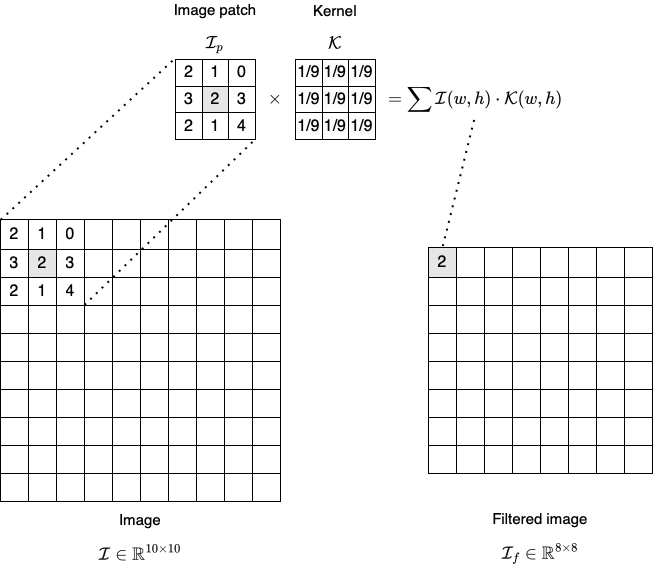

<br>

_**(Problem 1)**_ Now, implement a custom convolution function that takes an image and a kernel as inputs and returns the result of the convolution operation.

In [1]:
import numpy              as np
import numpy.linalg       as nl
import matplotlib.pyplot  as plt
import time
import cv2
import requests

def convolve(image, kernel):
    h_i, w_i = image.shape
    h_k, w_k = kernel.shape

    h_o = h_i - h_k + 1
    w_o = w_i - w_k + 1

    image_conv = np.zeros((h_o, w_o))

    # your code here ----------------------------------------------------------#
    for i in range(h_o):
        for j in range(w_o):
            image_conv[i, j] = np.sum(
                image[i:i+h_k, j:j+w_k] * kernel
            )
    # -------------------------------------------------------------------------#

    return image_conv

/Users/br4c3/Projects/linear-algebra-for-machine-and-deep-learning/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


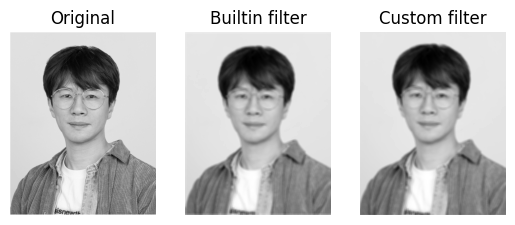

In [2]:
def load_image_from_url(url):
    response = requests.get(url)
    image_array = np.frombuffer(response.content, np.uint8)
    img = cv2.imdecode(image_array, cv2.IMREAD_COLOR)
    return img

def visualize(imgs, titles, cmap='gray'):
  n = len(imgs)
  fig, axs = plt.subplots(1, n)
  if n == 1:
    axs.imshow(imgs[0], cmap=cmap)
    axs.set_title(titles[0])
    axs.axis('off')
  else:
    for i in range(n):
      axs[i].imshow(imgs[i], cmap=cmap)
      axs[i].set_title(titles[i])
      axs[i].axis('off')
  plt.show()

img_link = "https://jonghank.github.io/jhk-2024.jpg"

img = load_image_from_url(img_link)
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

img_gray_raw = cv2.resize(img, None, fx=0.25, fy=0.25)

kernel_mean = 1/100 * np.ones((10,10), dtype=np.float16)

img_gray_flt_cv2 = cv2.filter2D(img_gray_raw, -1, kernel_mean)
img_gray_flt_cus = convolve(img_gray_raw, kernel_mean)

visualize([img_gray_raw, img_gray_flt_cv2, img_gray_flt_cus], ['Original', 'Builtin filter', 'Custom filter'])

<br>


---


## Padding

As shown in the image, when implementing convolution, you can observe that the image size decreases depending on the size of the kernel. For this reason, when you want to maintain the original image size after convolution, you need to expand the image before applying the convolution to match the size of the kernel. This is known as "Padding", and depending on how the expanded area is filled, there are different padding methods.

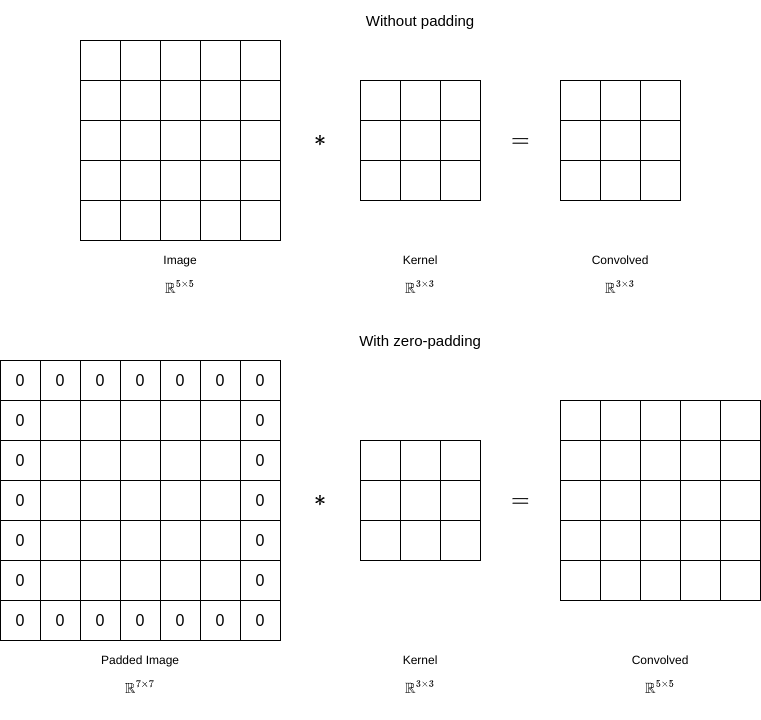

As illustrated above, filling with zeros is called "zero-padding", and there are other methods as well, such as filling the padding area by replicating the pixels at the edges.

<br>

_**(Problem 2)**_ Complete the image zero-padding function.

708 565
10 10


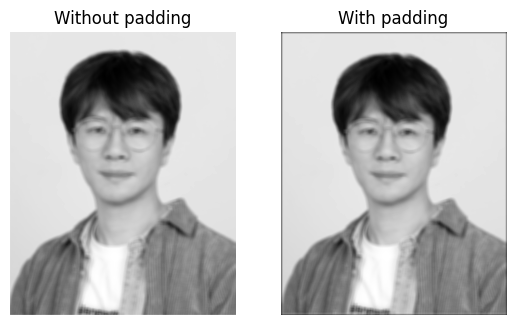

Original image                  :  (708, 565)
Convolved image without padding :  (699, 556)
Convolved image with padding    :  (708, 565)


In [3]:
def zero_padding(image, kernel):
    h_i, w_i = image.shape
    h_k, w_k = kernel.shape

    print(h_i, w_i)
    print(h_k, w_k)

    # your code here ----------------------------------------------------------#
    pad_h = h_k // 2
    pad_w = w_k // 2
    
    image_pad = np.zeros((
        h_i + 2 * pad_h,
        w_i + 2 * pad_w
    ))
    
    image_pad[
        pad_h : pad_h + h_i,
        pad_w : pad_w + w_i
    ] = image
    # -------------------------------------------------------------------------#

    return image_pad

def convolve_zero_padded(image, kernel):
    h_i, w_i = image.shape
    h_k, w_k = kernel.shape

    image_padded = zero_padding(image, kernel)
    image_conv = np.zeros((h_i, w_i))

    for i in range(h_i):
        for j in range(w_i):
            image_conv[i, j] = np.sum(image_padded[i : i + h_k, j : j + w_k] * kernel)

    return image_conv

img_gray_flt_cus_zp = convolve_zero_padded(img_gray_raw, kernel_mean)

visualize([img_gray_flt_cus,img_gray_flt_cus_zp], ['Without padding', 'With padding'])

print("Original image                  : ",img_gray_raw.shape)
print("Convolved image without padding : ",img_gray_flt_cus.shape)
print("Convolved image with padding    : ",img_gray_flt_cus_zp.shape)

<br>

---

## Matrix-wise implementation of image convolution

If you implemented the convolution using a `for` loop, you may notice that the operation is quite slow. This is due to the limitations of the Python language, as its core functions are not optimized for speed. On the other hand, libraries like NumPy, which are built on C, can perform matrix operations at much higher speeds. By leveraging NumPy's matrix operations, we can significantly improve the speed of the convolution operation.

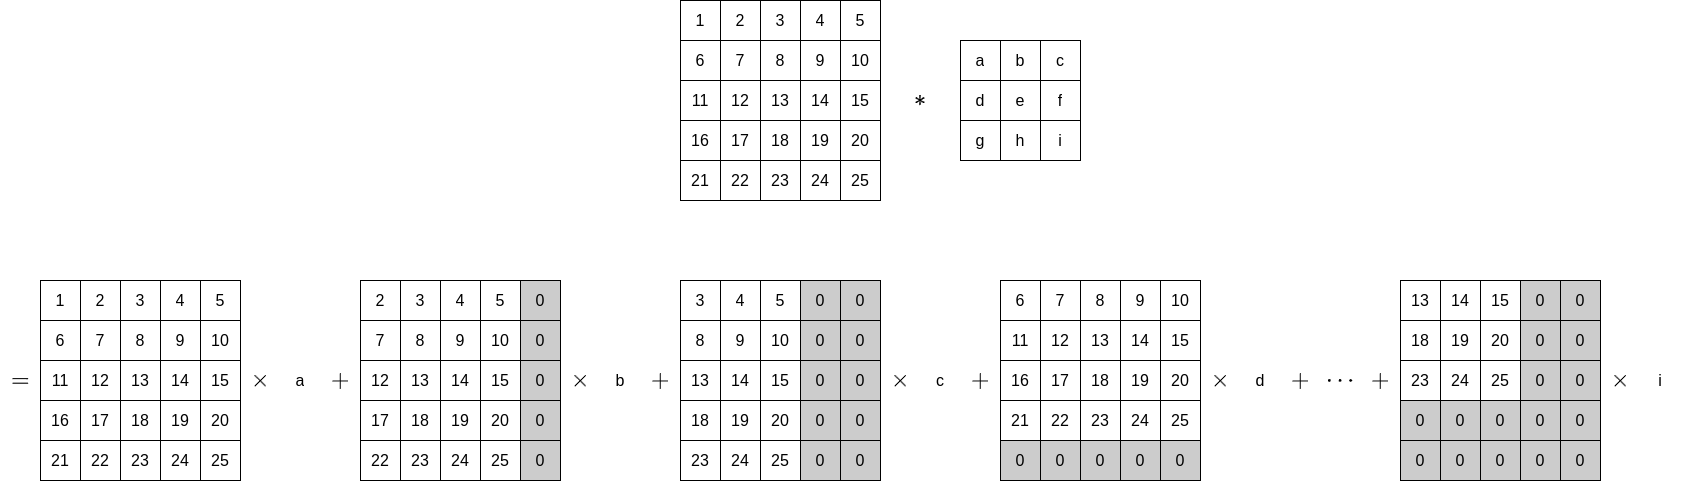

If the total number of elements in the kernel is $ N_k $, as shown above, the convolution can be represented as the weighted sum of $ N_k $ shifted images, where each image corresponds to a region of the input image. Now, let's implement the convolution operation using this approach and compare its runtime with the one implemented previously.

<br>

_**(Problem 3)**_ Implement the matrix-wise convolution function.

( Hint. Use `np.roll()` function. )

708 565
10 10
708 565
10 10


/var/folders/2p/hhtqy8b96_d6zjxc3jlbxhz80000gn/T/ipykernel_18164/3332967653.py:29: RuntimeWarning: divide by zero encountered in matmul
  result = image_mtx @ kernel_mtx
/var/folders/2p/hhtqy8b96_d6zjxc3jlbxhz80000gn/T/ipykernel_18164/3332967653.py:29: RuntimeWarning: overflow encountered in matmul
  result = image_mtx @ kernel_mtx
/var/folders/2p/hhtqy8b96_d6zjxc3jlbxhz80000gn/T/ipykernel_18164/3332967653.py:29: RuntimeWarning: invalid value encountered in matmul
  result = image_mtx @ kernel_mtx


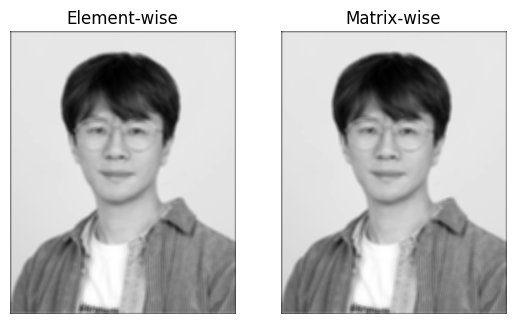

Element-wise elapsed time [s]   :  0.6822509765625
Matrix-wise elapsed time [s]    :  0.17864394187927246


In [4]:
def convolve_mtx(image, kernel):
    h_i, w_i = image.shape
    h_k, w_k = kernel.shape

    image_conv = np.zeros((h_i, w_i))

    # zero padding
    image_padded = zero_padding(image, kernel)

    # 각 convolution 영역을 한 줄로 펼친 행렬
    image_mtx = np.zeros((h_i * w_i, h_k * w_k))

    idx = 0

    for i in range(h_i):
        for j in range(w_i):
            patch = image_padded[
                i:i+h_k,
                j:j+w_k
            ]

            image_mtx[idx, :] = patch.reshape(-1)
            idx += 1

    # kernel 역시 1차원으로 펼침
    kernel_mtx = kernel.reshape(-1)

    # 행렬곱
    result = image_mtx @ kernel_mtx

    # 다시 이미지 모양으로 복원
    image_conv = result.reshape(h_i, w_i)

    return image_conv

start = time.time()
img_gray_flt_cus_zp  = convolve_zero_padded(img_gray_raw, kernel_mean)
elapsed_cus_zp = time.time() - start

start = time.time()
img_gray_flt_cus_mtx = convolve_mtx(img_gray_raw, kernel_mean)
elapsed_cus_mtx = time.time() - start

visualize([img_gray_flt_cus_zp,img_gray_flt_cus_mtx], ['Element-wise', 'Matrix-wise'])
print("Element-wise elapsed time [s]   : ", elapsed_cus_zp)
print("Matrix-wise elapsed time [s]    : ", elapsed_cus_mtx)


You could see that matrix-wise operations are relatively faster than element-wise operations. The difference in computation time becomes more pronounced as the image size increases.

<br>

---

## Image noise filtering

Let us design filters to remove noise from an image using convolution operations.

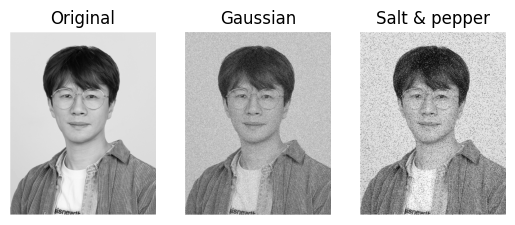

In [5]:
img_gray_noisy_gausian = img_gray_raw.copy() + 100*np.random.rand(*img_gray_raw.shape)
img_gray_noisy_salt_pepper = img_gray_raw.copy()

random_mask = np.random.rand(*img_gray_raw.shape)
salt_mask = np.where(random_mask > 0.95)
pepper_mask = np.where(random_mask < 0.05)
img_gray_noisy_salt_pepper[salt_mask] = 255
img_gray_noisy_salt_pepper[pepper_mask] = 0

visualize([img_gray_raw, img_gray_noisy_gausian, img_gray_noisy_salt_pepper], ['Original', 'Gaussian', 'Salt & pepper'])

<br>

---


### Gaussian blur


To implement Gaussian blur, the kernel should be constructed with elements corresponding to values of a Gaussian distribution, with the center of the kernel being the mean point.

$$
\mathcal{K}(w,h) = {1\over \sqrt{2\pi\sigma^2}}\exp{\Big(-{(w-c_w)^2 + (h-c_h)^2\over2\sigma^2}\Big)}
$$

Where $(c_w,c_h)$ is a center pixel of the kernel.

<br>

_**(Problem 4)**_ Implement the function that outputs the Gaussian kernel.

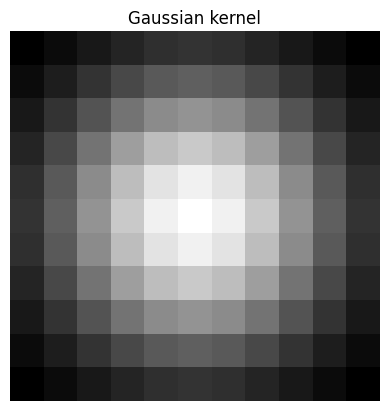

In [6]:
def kernel_gaussian(size, sigma):
    kernel = np.zeros((size, size))

    center = size // 2

    for i in range(size):
        for j in range(size):
            x = i - center
            y = j - center

            kernel[i, j] = np.exp(
                -(x*x + y*y) / (2 * sigma*sigma)
            )

    # 전체 합이 1이 되도록 정규화
    kernel = kernel / np.sum(kernel)

    return kernel

kernel_g = kernel_gaussian(11, 3)

visualize([kernel_g], ['Gaussian kernel'])

The results of Gaussian blur through this Gaussian kernel to a noisy image are as follows.

708 565
11 11


/var/folders/2p/hhtqy8b96_d6zjxc3jlbxhz80000gn/T/ipykernel_18164/3332967653.py:29: RuntimeWarning: divide by zero encountered in matmul
  result = image_mtx @ kernel_mtx
/var/folders/2p/hhtqy8b96_d6zjxc3jlbxhz80000gn/T/ipykernel_18164/3332967653.py:29: RuntimeWarning: overflow encountered in matmul
  result = image_mtx @ kernel_mtx
/var/folders/2p/hhtqy8b96_d6zjxc3jlbxhz80000gn/T/ipykernel_18164/3332967653.py:29: RuntimeWarning: invalid value encountered in matmul
  result = image_mtx @ kernel_mtx


708 565
11 11


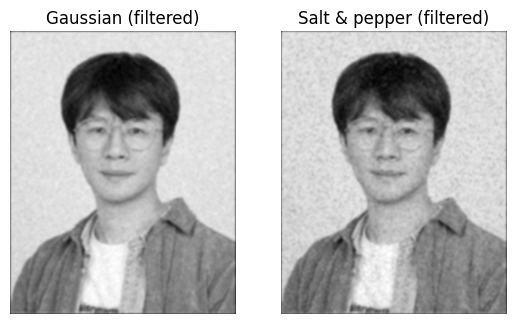

In [7]:
img_gray_flt_g_g  = convolve_mtx(img_gray_noisy_gausian, kernel_g)
img_gray_flt_sp_g = convolve_mtx(img_gray_noisy_salt_pepper, kernel_g)

visualize([img_gray_flt_g_g, img_gray_flt_sp_g], ['Gaussian (filtered)', 'Salt & pepper (filtered)'])

<br>

---

### Nonlinear filter : Median filter

The filters introduced earlier, such as the mean filter and Gaussian filter, are linear filters. However, there are also nonlinear filters where the operation between the kernel and the image patch is nonlinear. One of the most representative nonlinear filters is the Median filter, which outputs the median value among the elements of the image patch.

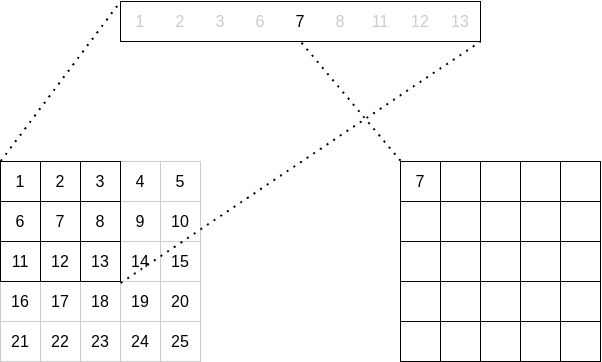

708 565
3 3
708 565
3 3


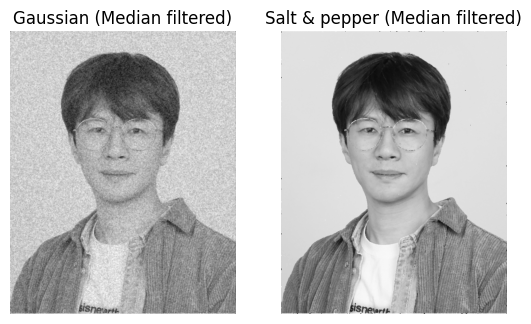

In [8]:
def median_filter(image, kernel_size):

    h_i, w_i = image.shape

    image_flt = np.zeros((h_i, w_i))

    image_padded = zero_padding(
        image,
        np.zeros((kernel_size, kernel_size))
    )

    for i in range(h_i):
        for j in range(w_i):
            patch = image_padded[
                i:i + kernel_size,
                j:j + kernel_size
            ]

            image_flt[i, j] = np.median(patch)

    return image_flt

img_gray_flt_g_m  = median_filter(img_gray_noisy_gausian, 3)
img_gray_flt_sp_m = median_filter(img_gray_noisy_salt_pepper, 3)

visualize([img_gray_flt_g_m, img_gray_flt_sp_m], ['Gaussian (Median filtered)', 'Salt & pepper (Median filtered)'])

As can be seen from the results above, the median filter performs well in removing salt-and-pepper noise. However, it is less effective at reducing gaussian noise.

_**(Problem 5)**_ Implement the nonlinear filters below.

---

### Bilateral Filter

The Bilateral Filter is a nonlinear filter designed to reduce image noise while preserving edges. Unlike the Gaussian Filter, it computes a weighted average by considering both the spatial distance and the intensity difference between pixels. Higher weights are assigned to pixels that are spatially close and have similar intensity values. The output pixel is calculated as follows:

$$
I_{\mathrm{out}}(p)=\frac{1}{W_p}\sum_{q\in\Omega_p}
\exp\left(-\frac{\|p-q\|^2}{2\sigma_s^2}-\frac{(I(p)-I(q))^2}{2\sigma_r^2}\right)I(q)
$$

$$
W_p=\sum_{q\in\Omega_p}
\exp\left(-\frac{\|p-q\|^2}{2\sigma_s^2}-\frac{(I(p)-I(q))^2}{2\sigma_r^2}\right)
$$

Here, $\Omega_p$ denotes the filtering window around pixel $p$, and $W_p$ is the normalization factor defined as the sum of the weights. The parameter $\sigma_s$ controls the influence of spatial distance, while $\sigma_r$ determines the sensitivity to intensity differences. By adjusting these parameters and the filter window size, the trade-off between noise reduction and edge preservation can be investigated.

( Tip: Use vectorized operations in NumPy. Ex.> **x[idxs,:]** or **x[:,idxs]** )

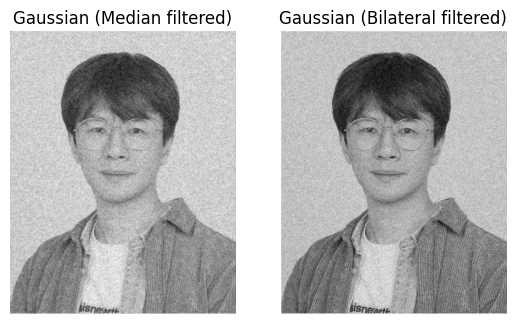

In [10]:
def bilateral_filter_vectorize( image, radius=2, sigma_s=2.0, sigma_r=25.0 ):
    img  = image.astype( np.float64 )
    h, w = img.shape

    out = np.zeros_like( img )

    k_y = np.arange( h )
    k_x = np.arange( w )

    w_sum     = np.zeros_like( img )
    value_sum = np.zeros_like( img )

    _min_idy = np.zeros( h ); _max_idy = np.ones( h ) * (h-1)
    _min_idx = np.zeros( w ); _max_idx = np.ones( w ) * (w-1)

    radius = int(radius)
    for dy in range( -radius, radius+1 ):
        for dx in range( -radius, radius+1 ):

            # your code here --------------------------------------------------#
            idy = np.clip(k_y + dy, _min_idy, _max_idy).astype(int)
            idx = np.clip(k_x + dx, _min_idx, _max_idx).astype(int)

            shifted = img[np.ix_(idy, idx)]

            w_s = np.exp(
                -(dx * dx + dy * dy) / (2 * sigma_s * sigma_s)
            )

            diff = shifted - img

            w_r = np.exp(
                -(diff * diff) / (2 * sigma_r * sigma_r)
            )

            weight = w_s * w_r

            w_sum += weight
            value_sum += weight * shifted
            # -----------------------------------------------------------------#

    out[:,:] = value_sum / w_sum

    return out

radius  = 2.0
sigma_s = 2.0
sigma_r = 25.0

img_gray_flt_g_bi  = bilateral_filter_vectorize( img_gray_noisy_gausian, radius=radius, sigma_s=sigma_s, sigma_r=sigma_r )

visualize([img_gray_flt_g_m, img_gray_flt_g_bi], ['Gaussian (Median filtered)', 'Gaussian (Bilateral filtered)'])

### Wiener Filter

The Wiener Filter is an adaptive filter particularly effective for reducing **additive Gaussian noise** by considering the local statistical properties of an image. Unlike conventional averaging filters, it adjusts the degree of smoothing based on the local mean and variance of pixel intensities. In regions with low variance, stronger smoothing is applied, while regions with high variance, such as edges, are preserved to a greater extent.

The filtered pixel intensity is calculated as follows:

$$
I_{\mathrm{out}}(p)=\mu_p+
\frac{\max(\sigma_p^2-\sigma_n^2,\,0)}
{\max(\sigma_p^2,\,\epsilon)}
\left(I(p)-\mu_p\right)
$$

$$
\mu_p=\frac{1}{N}\sum_{q\in\Omega_p}I(q),\qquad
\sigma_p^2=\frac{1}{N}\sum_{q\in\Omega_p}I(q)^2-\mu_p^2
$$

Here, $\Omega_p$ denotes the local filtering window containing $N$ pixels, while $\mu_p$ and $\sigma_p^2$ represent the local mean and variance, respectively. The parameter $\sigma_n^2$ represents the Gaussian noise variance, and $\epsilon$ is a small positive constant used to prevent division by zero. By adjusting the window size and noise variance, the trade-off between noise reduction and image detail preservation can be investigated.

( Hint: Use `convolve_mtx()` )

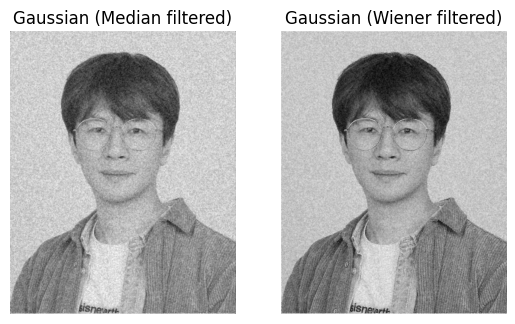

In [11]:
def wiener_filter(image, window_size=3, noise_var=None, eps=1e-12):
    img = image.astype(np.float64)

    kernel = np.ones((window_size, window_size), dtype=np.float64)
    kernel /= window_size * window_size

    local_mean = cv2.filter2D(
        img,
        -1,
        kernel,
        borderType=cv2.BORDER_REFLECT
    )

    local_mean_sq = cv2.filter2D(
        img * img,
        -1,
        kernel,
        borderType=cv2.BORDER_REFLECT
    )

    local_var = local_mean_sq - local_mean * local_mean

    if noise_var is None:
        noise_var = np.mean(local_var)

    out = local_mean + (
        np.maximum(local_var - noise_var, 0)
        / (local_var + eps)
    ) * (img - local_mean)

    return out

img_gray_flt_g_wi = wiener_filter( img_gray_noisy_gausian )

visualize([img_gray_flt_g_m, img_gray_flt_g_wi], ['Gaussian (Median filtered)', 'Gaussian (Wiener filtered)'])

_**(Problem 6)**_ Evaluate filter performance with PSNR and SSIM.

---

### PSNR (Peak Signal-to-Noise Ratio) and SSIM (Structural Similarity Index Measure)

Since it is difficult to quantitatively evaluate the effectiveness of image filtering through visual inspection alone, **PSNR** and **SSIM** are commonly used to measure the quality of filtered images. PSNR evaluates the pixel-wise difference between the original and filtered images based on the Mean Squared Error (MSE).

A higher PSNR indicates a smaller reconstruction error.

$$
\mathrm{PSNR}=10\log_{10}\left(\frac{MAX_I^2}{\mathrm{MSE}}\right),\quad
\mathrm{MSE}=\frac{1}{MN}\sum_{i=1}^{M}\sum_{j=1}^{N}(I_{ij}-\hat I_{ij})^2
$$

SSIM evaluates image similarity by considering local luminance, contrast, and structural information. An SSIM value closer to 1 indicates greater similarity to the original image.

$$
\mathrm{SSIM}=
\frac{(2\mu_I\mu_{\hat I}+C_1)(2\sigma_{I\hat I}+C_2)}
{(\mu_I^2+\mu_{\hat I}^2+C_1)(\sigma_I^2+\sigma_{\hat I}^2+C_2)}
$$

Here, $\mu$, $\sigma^2$, and $\sigma_{I\hat I}$ denote the local mean, variance, and covariance, respectively, while $C_1$ and $C_2$ are constants used for numerical stability. The overall SSIM is obtained by averaging local SSIM values.

**You do not need to implement these metrics yourself.** Instead, use `peak_signal_noise_ratio()` and `structural_similarity()` from `skimage.metrics` to evaluate and compare the filtering results against the original image.

( Tip: You need to tune the parameters of each filter. )

In [13]:
from skimage.metrics import peak_signal_noise_ratio
from skimage.metrics import structural_similarity

data_range = img_gray_raw.max() - img_gray_raw.min()

psnr_g_m = peak_signal_noise_ratio(
    img_gray_raw, img_gray_flt_g_m,
    data_range=data_range
)

ssim_g_m = structural_similarity(
    img_gray_raw, img_gray_flt_g_m,
    data_range=data_range
)

psnr_g_bi = peak_signal_noise_ratio(
    img_gray_raw, img_gray_flt_g_bi,
    data_range=data_range
)

ssim_g_bi = structural_similarity(
    img_gray_raw, img_gray_flt_g_bi,
    data_range=data_range
)

psnr_g_wi = peak_signal_noise_ratio(
    img_gray_raw, img_gray_flt_g_wi,
    data_range=data_range
)

ssim_g_wi = structural_similarity(
    img_gray_raw, img_gray_flt_g_wi,
    data_range=data_range
)

print("Median Filter")
print("PSNR :", psnr_g_m)
print("SSIM :", ssim_g_m)

print("\nBilateral Filter")
print("PSNR :", psnr_g_bi)
print("SSIM :", ssim_g_bi)

print("\nWiener Filter")
print("PSNR :", psnr_g_wi)
print("SSIM :", ssim_g_wi)

Median Filter
PSNR : 13.431930114096431
SSIM : 0.3435098951797738

Bilateral Filter
PSNR : 13.177717223098313
SSIM : 0.2941135781409345

Wiener Filter
PSNR : 13.63760246438031
SSIM : 0.49571304791497545
